
<div style="background:linear-gradient(120deg,#F0EAF8,#E4DDF2); padding:32px; border-radius:10px; border-left:6px solid #7652A3;">

<p style="font-family:'Poppins',sans-serif; font-size:12px; font-weight:700; letter-spacing:2px; color:#8064A6;">
UCS420 · COGNITIVE COMPUTING
</p>

<h1 style="font-family:'Poppins',sans-serif; font-size:42px; font-weight:800; color:#39244F; margin:14px 0 4px;">
GLYVIA
</h1>

<p style="font-family:'Poppins',sans-serif; font-size:19px; font-weight:600; color:#725392; margin:0;">
Diabetes Care Cognitive Assistant
</p>

<div style="height:2px; background:#CBBBDD; margin:22px 0;"></div>

<p style="font-family:'Inter',sans-serif; font-size:14px; color:#574A65; line-height:1.8;">
An intelligent healthcare assistant integrating Natural Language Processing, Machine Learning and knowledge-based reasoning for diabetes-related query understanding.
</p>

<p style="font-family:'Poppins',sans-serif; font-size:12px; font-weight:700; color:#8064A6; margin-top:24px;">
ASSIGNMENT 10 &nbsp; | &nbsp; 2026
</p>

</div>


In [1]:
%pip install -q gradio nltk scikit-learn seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import gradio as gr

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("GLYVIA initialized successfully!")

GLYVIA initialized successfully!


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
01 | NLP Resource Initialization
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Preparing the language-processing resources required for text preprocessing.
</p>

In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english')) - {'no', 'not', 'nor'}
lemmatizer = WordNetLemmatizer()

print("NLP resources ready!")

NLP resources ready!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
02 | Diabetes Query Dataset
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Building a labelled query corpus covering eight core areas of diabetes care.
</p>

In [3]:
data = [
    # Symptoms
    ("What are common symptoms of diabetes?", "symptoms"),
    ("Why do I feel thirsty all the time?", "symptoms"),
    ("Can diabetes cause frequent urination?", "symptoms"),
    ("What are early warning signs of diabetes?", "symptoms"),
    ("Why do diabetic patients feel tired?", "symptoms"),
    ("Can diabetes cause blurred vision?", "symptoms"),
    ("What are signs of low blood sugar?", "symptoms"),
    ("How can I recognize high blood sugar?", "symptoms"),
    ("What physical changes indicate diabetes?", "symptoms"),
    ("Can unexplained weight loss indicate diabetes?", "symptoms"),

    # Glucose monitoring
    ("How do I monitor my blood sugar?", "glucose_monitoring"),
    ("How can I check my blood sugar?", "glucose_monitoring"),
    ("When should I check my glucose levels?", "glucose_monitoring"),
    ("How does a glucose meter work?", "glucose_monitoring"),
    ("What is continuous glucose monitoring?", "glucose_monitoring"),
    ("How often should blood sugar be tested?", "glucose_monitoring"),
    ("What is an HbA1c test?", "glucose_monitoring"),
    ("How can I track my glucose readings?", "glucose_monitoring"),
    ("What are normal blood glucose levels?", "glucose_monitoring"),
    ("How is blood sugar measured?", "glucose_monitoring"),

    # Medication
    ("What medications are used for diabetes?", "medication"),
    ("What is metformin prescribed for?", "medication"),
    ("Why do diabetic patients need insulin?", "medication"),
    ("How should diabetes medication be managed?", "medication"),
    ("What are common diabetes medicines?", "medication"),
    ("Can I stop taking prescribed diabetes medicine?", "medication"),
    ("What does insulin do?", "medication"),
    ("How is insulin administered?", "medication"),
    ("Are there different types of insulin?", "medication"),
    ("Why is medication important in diabetes?", "medication"),

    # Nutrition
    ("What foods should diabetics eat?", "nutrition"),
    ("Which foods help control blood sugar?", "nutrition"),
    ("Should people with diabetes avoid sugar?", "nutrition"),
    ("What is a balanced diabetic diet?", "nutrition"),
    ("Are whole grains suitable for diabetes?", "nutrition"),
    ("How do carbohydrates affect blood glucose?", "nutrition"),
    ("What fruits can people with diabetes eat?", "nutrition"),
    ("How does diet affect diabetes?", "nutrition"),
    ("What are healthy meal choices for diabetics?", "nutrition"),
    ("Can people with diabetes eat rice?", "nutrition"),

    # Exercise
    ("How does exercise affect blood glucose?", "exercise"),
    ("Can walking help manage diabetes?", "exercise"),
    ("What physical activities are suitable for diabetics?", "exercise"),
    ("Does physical activity lower blood sugar?", "exercise"),
    ("How much exercise is recommended for diabetes?", "exercise"),
    ("Can exercise affect insulin sensitivity?", "exercise"),
    ("Is cycling good for people with diabetes?", "exercise"),
    ("How does physical activity help diabetes?", "exercise"),
    ("Should diabetics exercise daily?", "exercise"),
    ("Can exercise cause low blood sugar?", "exercise"),

    # Complications
    ("What complications can diabetes cause?", "complications"),
    ("Can diabetes damage the kidneys?", "complications"),
    ("Does diabetes affect eyesight?", "complications"),
    ("What happens if blood sugar stays high?", "complications"),
    ("Can diabetes cause nerve damage?", "complications"),
    ("What are the long term effects of diabetes?", "complications"),
    ("Can diabetes affect the heart?", "complications"),
    ("What is diabetic neuropathy?", "complications"),
    ("How does diabetes affect blood vessels?", "complications"),
    ("Can uncontrolled diabetes damage organs?", "complications"),

    # Prevention
    ("How can I reduce my risk of diabetes?", "prevention"),
    ("How can type 2 diabetes be prevented?", "prevention"),
    ("Does maintaining a healthy weight reduce diabetes risk?", "prevention"),
    ("Can lifestyle changes prevent diabetes?", "prevention"),
    ("How can I lower my chances of developing diabetes?", "prevention"),
    ("What habits help reduce diabetes risk?", "prevention"),
    ("Can regular exercise reduce diabetes risk?", "prevention"),
    ("Does healthy eating help prevent diabetes?", "prevention"),
    ("How can prediabetes be managed?", "prevention"),
    ("What lifestyle changes lower diabetes risk?", "prevention"),

    # General information
    ("What is diabetes mellitus?", "general_info"),
    ("What is type 1 diabetes?", "general_info"),
    ("What is type 2 diabetes?", "general_info"),
    ("Why does blood glucose increase in diabetes?", "general_info"),
    ("What role does insulin play in diabetes?", "general_info"),
    ("What causes diabetes mellitus?", "general_info"),
    ("What happens in the body during diabetes?", "general_info"),
    ("Is diabetes a chronic condition?", "general_info"),
    ("What is the difference between type 1 and type 2 diabetes?", "general_info"),
    ("Can diabetes be managed?", "general_info"),

    # Additional examples
    ("Why am I always thirsty?", "symptoms"),
    ("What are the warning signs of high glucose?", "symptoms"),
    ("How do I measure blood sugar at home?", "glucose_monitoring"),
    ("How can I monitor glucose throughout the day?", "glucose_monitoring"),
    ("What is the purpose of HbA1c monitoring?", "glucose_monitoring"),
    ("How does metformin help manage diabetes?", "medication"),
    ("What should I know about diabetes prescriptions?", "medication"),
    ("Can diabetes medicine have side effects?", "medication"),
    ("Which carbohydrates should diabetics choose?", "nutrition"),
    ("How can I plan meals for diabetes?", "nutrition"),
    ("Are sugary drinks suitable for diabetics?", "nutrition"),
    ("Can regular walking improve blood sugar?", "exercise"),
    ("What workouts are safe for diabetes?", "exercise"),
    ("How can exercise improve glucose control?", "exercise"),
    ("Can diabetes lead to kidney disease?", "complications"),
    ("What health problems are linked to diabetes?", "complications"),
    ("Can high glucose harm the nerves?", "complications"),
    ("How can I prevent developing type 2 diabetes?", "prevention"),
    ("Can weight management lower diabetes risk?", "prevention"),
    ("What daily habits support diabetes prevention?", "prevention"),
    ("Explain diabetes in simple terms.", "general_info"),
    ("How does the pancreas relate to diabetes?", "general_info"),
    ("Why is insulin important for the body?", "general_info"),
    ("What is the difference between diabetes types?", "general_info")
]

df = pd.DataFrame(data, columns=["query", "intent"])

print("Total queries:", len(df))
print("Unique intents:", df["intent"].nunique())

Total queries: 104
Unique intents: 8


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
03 | Dataset Validation
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Validating query uniqueness, completeness and intent distribution before preprocessing.
</p>

In [4]:
print("Total queries:", len(df))
print("Unique intents:", df["intent"].nunique())
print("Duplicate queries:", df["query"].duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

display(df["intent"].value_counts().to_frame("Query Count"))

assert len(df) == 104
assert df["intent"].nunique() == 8
assert df["query"].is_unique
assert df.isnull().sum().sum() == 0

print("All validation checks passed!")

Total queries: 104
Unique intents: 8
Duplicate queries: 0
Missing values: 0


,Query Count
intent,
general_info,14
glucose_monitoring,13
nutrition,13
medication,13
complications,13
exercise,13
prevention,13
symptoms,12


All validation checks passed!


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
04 | Hierarchical Intent Taxonomy
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Structuring diabetes-related queries into four major categories and eight specific subcategories.
</p>

In [5]:
taxonomy = {
    "Clinical Indicators": {
        "Symptoms": "symptoms",
        "Complications": "complications"
    },
    "Monitoring and Treatment": {
        "Glucose Assessment": "glucose_monitoring",
        "Medication Management": "medication"
    },
    "Lifestyle Management": {
        "Nutrition": "nutrition",
        "Physical Activity": "exercise"
    },
    "Health Awareness": {
        "Risk Reduction": "prevention",
        "Diabetes Fundamentals": "general_info"
    }
}

for category, subcategories in taxonomy.items():
    print(category)
    for subcategory, intent in subcategories.items():
        print(f"  └── {subcategory}: {intent}")

Clinical Indicators
  └── Symptoms: symptoms
  └── Complications: complications
Monitoring and Treatment
  └── Glucose Assessment: glucose_monitoring
  └── Medication Management: medication
Lifestyle Management
  └── Nutrition: nutrition
  └── Physical Activity: exercise
Health Awareness
  └── Risk Reduction: prevention
  └── Diabetes Fundamentals: general_info


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
05 | Diabetes Domain Knowledge
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Defining important diabetes-related medical concepts and their meanings.
</p>

In [6]:
concepts = {
    "Diabetes": "A chronic condition involving elevated blood glucose.",
    "Insulin": "A hormone that helps regulate blood glucose.",
    "Pancreas": "An organ responsible for producing insulin.",
    "Glucose": "The primary sugar used by the body for energy.",
    "Blood Glucose": "The concentration of glucose in the bloodstream.",
    "Hyperglycemia": "Abnormally high blood glucose.",
    "Hypoglycemia": "Abnormally low blood glucose.",
    "Carbohydrates": "Nutrients broken down into glucose.",
    "Exercise": "Physical activity that influences glucose utilization.",
    "Metformin": "A medication commonly used in type 2 diabetes.",
    "HbA1c": "A measure of average blood glucose over approximately three months.",
    "Complications": "Health problems associated with diabetes."
}

concept_df = pd.DataFrame(
    concepts.items(),
    columns=["Concept", "Description"]
)

display(concept_df)

,Concept,Description
0,Diabetes,A chronic condition involving elevated blood g...
1,Insulin,A hormone that helps regulate blood glucose.
2,Pancreas,An organ responsible for producing insulin.
3,Glucose,The primary sugar used by the body for energy.
4,Blood Glucose,The concentration of glucose in the bloodstream.
5,Hyperglycemia,Abnormally high blood glucose.
6,Hypoglycemia,Abnormally low blood glucose.
7,Carbohydrates,Nutrients broken down into glucose.
8,Exercise,Physical activity that influences glucose util...
9,Metformin,A medication commonly used in type 2 diabetes.


<h3 style="font-family:'Poppins',sans-serif;font-size:20px;font-weight:700;color:#7050A0;">
5.1 | Semantic Relationships
</h3>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Representing meaningful connections between diabetes-related medical concepts.
</p>

In [7]:
relationships = [
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "regulates", "Blood Glucose"),
    ("Glucose", "contributes_to", "Blood Glucose"),
    ("Diabetes", "affects", "Insulin"),
    ("Diabetes", "associated_with", "Hyperglycemia"),
    ("Diabetes", "may_involve", "Hypoglycemia"),
    ("Carbohydrates", "break_down_into", "Glucose"),
    ("Exercise", "influences", "Blood Glucose"),
    ("Metformin", "helps_manage", "Diabetes"),
    ("HbA1c", "reflects_average", "Blood Glucose"),
    ("Hyperglycemia", "associated_with", "Complications"),
    ("Hypoglycemia", "involves_low_levels_of", "Blood Glucose"),
    ("Diabetes", "monitored_using", "HbA1c"),
    ("Insulin", "helps_control", "Hyperglycemia")
]

relationship_df = pd.DataFrame(
    relationships,
    columns=["Source", "Relationship", "Target"]
)

display(relationship_df)

print("Total semantic relationships:", len(relationship_df))

,Source,Relationship,Target
0,Pancreas,produces,Insulin
1,Insulin,regulates,Blood Glucose
2,Glucose,contributes_to,Blood Glucose
3,Diabetes,affects,Insulin
4,Diabetes,associated_with,Hyperglycemia
5,Diabetes,may_involve,Hypoglycemia
6,Carbohydrates,break_down_into,Glucose
7,Exercise,influences,Blood Glucose
8,Metformin,helps_manage,Diabetes
9,HbA1c,reflects_average,Blood Glucose


Total semantic relationships: 14


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
06 | NLP Text Preprocessing
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Cleaning and normalizing user queries to prepare them for machine learning-based intent classification.
</p>

In [8]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return tokens

df["processed_query"] = df["query"].apply(preprocess_text)

display(df[["query", "processed_query", "intent"]].head(10))

,query,processed_query,intent
0,What are common symptoms of diabetes?,"[common, symptom, diabetes]",symptoms
1,Why do I feel thirsty all the time?,"[feel, thirsty, time]",symptoms
2,Can diabetes cause frequent urination?,"[diabetes, cause, frequent, urination]",symptoms
3,What are early warning signs of diabetes?,"[early, warning, sign, diabetes]",symptoms
4,Why do diabetic patients feel tired?,"[diabetic, patient, feel, tired]",symptoms
5,Can diabetes cause blurred vision?,"[diabetes, cause, blurred, vision]",symptoms
6,What are signs of low blood sugar?,"[sign, low, blood, sugar]",symptoms
7,How can I recognize high blood sugar?,"[recognize, high, blood, sugar]",symptoms
8,What physical changes indicate diabetes?,"[physical, change, indicate, diabetes]",symptoms
9,Can unexplained weight loss indicate diabetes?,"[unexplained, weight, loss, indicate, diabetes]",symptoms


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
07 | TF-IDF Feature Extraction
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Transforming processed queries into numerical feature vectors to capture the importance of individual words and word combinations.
</p>

In [9]:
X = df["processed_query"].apply(lambda tokens: " ".join(tokens))
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])

Training samples: 83
Testing samples: 21
TF-IDF features: 316


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
08 | Machine Learning Intent Classification
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Training a Logistic Regression model to categorize diabetes-related queries into the eight defined intents.
</p>

In [10]:
model = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_tfidf, y_train)

predictions = model.predict(X_test_tfidf)

print("Model training completed!")
print("Number of intent classes:", len(model.classes_))

Model training completed!
Number of intent classes: 8


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
09 | Model Performance Evaluation
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Measuring classification performance using accuracy, precision, recall, F1-score and confusion matrix analysis.
</p>

In [11]:
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average="weighted", zero_division=0)
recall = recall_score(y_test, predictions, average="weighted", zero_division=0)
f1 = f1_score(y_test, predictions, average="weighted", zero_division=0)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics.round(4))

,Metric,Score
0,Accuracy,0.7619
1,Precision,0.8381
2,Recall,0.7619
3,F1-Score,0.7492


In [12]:
print(classification_report(
    y_test,
    predictions,
    labels=model.classes_,
    zero_division=0
))

                    precision    recall  f1-score   support

     complications       1.00      0.50      0.67         2
          exercise       0.50      0.50      0.50         2
      general_info       1.00      0.67      0.80         3
glucose_monitoring       0.60      1.00      0.75         3
        medication       0.60      1.00      0.75         3
         nutrition       1.00      0.33      0.50         3
        prevention       1.00      1.00      1.00         3
          symptoms       1.00      1.00      1.00         2

          accuracy                           0.76        21
         macro avg       0.84      0.75      0.75        21
      weighted avg       0.84      0.76      0.75        21



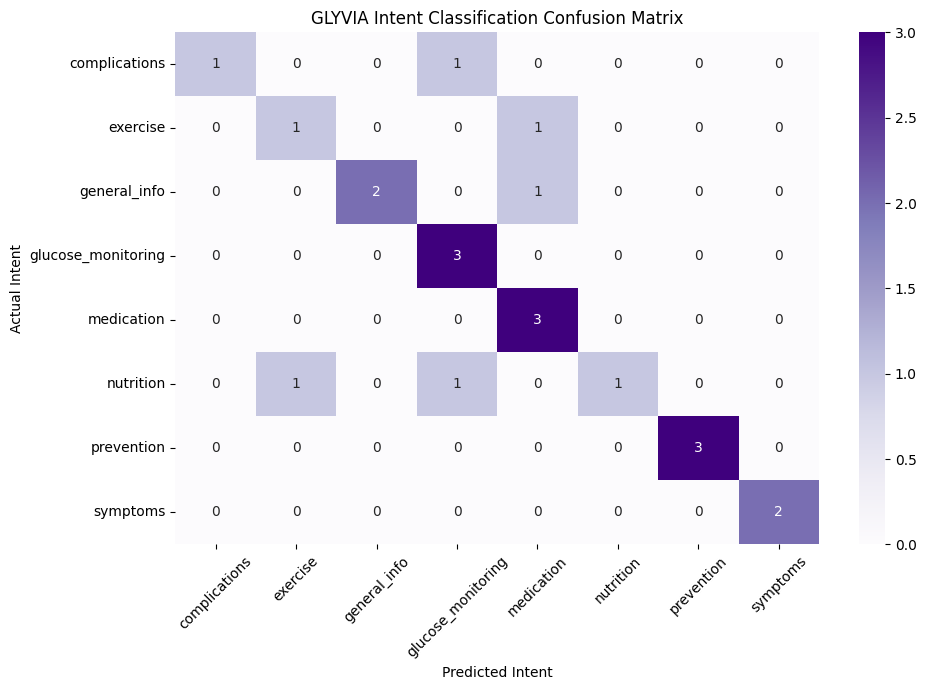

In [13]:
cm = confusion_matrix(y_test, predictions, labels=model.classes_)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("GLYVIA Intent Classification Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
10 | Domain-Specific Knowledge Base
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Creating an intent-linked information repository to support relevant and consistent responses to diabetes-related queries.
</p>

In [14]:
knowledge_base = {
    "symptoms": """
    Common symptoms of diabetes include increased thirst, frequent urination,
    unexplained weight loss, fatigue and blurred vision. Some people may have
    few or no noticeable symptoms. Symptoms alone cannot confirm diabetes;
    medical testing is required.
    """,

    "glucose_monitoring": """
    Blood glucose can be monitored using a blood glucose meter or a continuous
    glucose monitoring system. HbA1c estimates average blood glucose over
    approximately two to three months. Monitoring frequency and target levels
    should be determined with a healthcare professional.
    """,

    "medication": """
    Diabetes medications depend on the type of diabetes and individual needs.
    Metformin is commonly used in type 2 diabetes, while insulin is essential
    for people with type 1 diabetes and may be prescribed in other cases.
    Medication decisions must be made with a healthcare professional.
    """,

    "nutrition": """
    Diabetes nutrition management generally emphasizes balanced meals,
    appropriate portions, high-fibre foods, vegetables, whole grains and
    mindful carbohydrate intake. Individual dietary needs vary, so a
    personalized meal plan can be developed with a qualified professional.
    """,

    "exercise": """
    Regular physical activity can improve insulin sensitivity and support
    blood glucose management. Walking, cycling and other suitable activities
    may help. Exercise plans should account for individual health conditions
    and the risk of low blood glucose.
    """,

    "complications": """
    Poorly controlled diabetes can increase the risk of cardiovascular
    disease, kidney disease, nerve damage and eye problems. Regular health
    check-ups and appropriate glucose management can help reduce these risks.
    """,

    "prevention": """
    Type 2 diabetes risk may be reduced through regular physical activity,
    balanced nutrition, maintaining a healthy weight and routine health
    screening. Type 1 diabetes currently has no established prevention method.
    """,

    "general_info": """
    Diabetes mellitus is a chronic condition affecting how the body regulates
    blood glucose. Type 1 diabetes involves insufficient insulin production,
    while type 2 diabetes involves insulin resistance and often reduced insulin
    production. Management depends on the type and individual circumstances.
    """
}

assert set(knowledge_base.keys()) == set(df["intent"].unique())

print("Knowledge base initialized successfully!")
print("Available intent resources:", len(knowledge_base))

Knowledge base initialized successfully!
Available intent resources: 8


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
11 | Rule-Based Reasoning
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Combining predefined safety rules with machine-learning predictions to determine how incoming healthcare queries should be handled.
</p>

In [15]:
emergency_keywords = [
    "unconscious",
    "passed out",
    "seizure",
    "cannot breathe",
    "difficulty breathing",
    "chest pain",
    "severe confusion",
    "unresponsive"
]

domain_keywords = {
    "diabetes", "diabetic", "glucose", "blood sugar",
    "insulin", "pancreas", "metformin", "hba1c",
    "hyperglycemia", "hypoglycemia", "carbohydrate",
    "nutrition", "exercise", "thirst", "urination",
    "symptom", "complication", "medication", "glucose meter",
    "blood glucose", "sugar level", "prediabetes"
}

def reasoning_engine(query):
    text = query.lower()

    if any(keyword in text for keyword in emergency_keywords):
        return (
            "EMERGENCY",
            "This may indicate a medical emergency. Seek immediate emergency "
            "medical assistance. Do not delay care while using this assistant."
        )

    if not any(keyword in text for keyword in domain_keywords):
        return (
            "UNSUPPORTED",
            "This query appears outside GLYVIA's diabetes-care domain. "
            "Please ask a question related to diabetes care."
        )

    processed_tokens = preprocess_text(query)
    processed = " ".join(processed_tokens)
    features = tfidf.transform([processed])

    probabilities = model.predict_proba(features)[0]
    confidence = float(max(probabilities))

    # Rule: too little information, or very uncertain prediction
    if len(processed_tokens) < 2 or confidence < 0.20:
        return (
            "LOW_CONFIDENCE",
            "I could not confidently identify your intent. "
            "Please rephrase your diabetes-related question."
        )

    predicted_intent = model.predict(features)[0]

    response = knowledge_base[predicted_intent]

    if predicted_intent == "medication":
        response += (
            "\n\nSafety note: Do not change or stop prescribed medication "
            "without consulting your healthcare professional."
        )

    return predicted_intent, response


print("GLYVIA reasoning engine initialized successfully!")

GLYVIA reasoning engine initialized successfully!


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
12 | Integrated Cognitive Assistant
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Integrating natural language processing, intent classification, rule-based reasoning and knowledge retrieval into a unified assistant.
</p>

In [16]:
def glyvia_assistant(query):
    if not query or not query.strip():
        return "Please enter a question about diabetes care."

    intent, response = reasoning_engine(query)

    return f"""
GLYVIA | Diabetes Care Assistant

Detected Intent: {intent}

Response:
{response}
"""


print(glyvia_assistant("What is diabetes mellitus?"))


GLYVIA | Diabetes Care Assistant

Detected Intent: general_info

Response:

    Diabetes mellitus is a chronic condition affecting how the body regulates
    blood glucose. Type 1 diabetes involves insufficient insulin production,
    while type 2 diabetes involves insulin resistance and often reduced insulin
    production. Management depends on the type and individual circumstances.
    



In [17]:
test_queries = [
    "What are common symptoms of diabetes?",
    "How can I monitor my blood glucose?",
    "Tell me about football",
    "I am unconscious and having a seizure"
]

for query in test_queries:
    print("\nQuery:", query)
    print(glyvia_assistant(query))
    print("-" * 60)


Query: What are common symptoms of diabetes?

GLYVIA | Diabetes Care Assistant

Detected Intent: symptoms

Response:

    Common symptoms of diabetes include increased thirst, frequent urination,
    unexplained weight loss, fatigue and blurred vision. Some people may have
    few or no noticeable symptoms. Symptoms alone cannot confirm diabetes;
    medical testing is required.
    

------------------------------------------------------------

Query: How can I monitor my blood glucose?

GLYVIA | Diabetes Care Assistant

Detected Intent: glucose_monitoring

Response:

    Blood glucose can be monitored using a blood glucose meter or a continuous
    glucose monitoring system. HbA1c estimates average blood glucose over
    approximately two to three months. Monitoring frequency and target levels
    should be determined with a healthcare professional.
    

------------------------------------------------------------

Query: Tell me about football

GLYVIA | Diabetes Care Assistant

De

In [18]:
additional_tests = [
    ("What medications are used for diabetes?", "medication"),
    ("What foods should diabetics eat?", "nutrition"),
    ("Can walking help manage blood sugar?", "exercise"),
    ("Can diabetes damage the kidneys?", "complications"),
    ("How can I reduce my risk of diabetes?", "prevention"),
    ("What is type 1 diabetes?", "general_info"),
    ("Why am I always thirsty?", "symptoms"),
    ("How can I track my glucose readings?", "glucose_monitoring")
]

additional_results = []

for query, expected in additional_tests:
    predicted, response = reasoning_engine(query)
    additional_results.append({
        "Query": query,
        "Expected": expected,
        "Predicted": predicted,
        "Result": "PASS" if predicted == expected else "CHECK"
    })

additional_df = pd.DataFrame(additional_results)
display(additional_df)

print("Additional tests passed:",
      (additional_df["Result"] == "PASS").sum(),
      "out of", len(additional_df))

,Query,Expected,Predicted,Result
0,What medications are used for diabetes?,medication,medication,PASS
1,What foods should diabetics eat?,nutrition,nutrition,PASS
2,Can walking help manage blood sugar?,exercise,LOW_CONFIDENCE,CHECK
3,Can diabetes damage the kidneys?,complications,complications,PASS
4,How can I reduce my risk of diabetes?,prevention,prevention,PASS
5,What is type 1 diabetes?,general_info,general_info,PASS
6,Why am I always thirsty?,symptoms,symptoms,PASS
7,How can I track my glucose readings?,glucose_monitoring,glucose_monitoring,PASS


Additional tests passed: 7 out of 8


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
13 | Comprehensive System Testing
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;">
Validating intent recognition, response retrieval, query handling and safety rules across multiple test scenarios.
</p>

In [19]:
test_cases = [
    ("What are common symptoms of diabetes?", "symptoms"),
    ("How can I monitor my blood glucose?", "glucose_monitoring"),
    ("What medications are used for diabetes?", "medication"),
    ("What foods should diabetics eat?", "nutrition"),
    ("How does exercise affect blood glucose?", "exercise"),
    ("What complications can diabetes cause?", "complications"),
    ("How can I reduce my risk of diabetes?", "prevention"),
    ("What is diabetes mellitus?", "general_info"),
    ("How can I track my glucose readings?", "glucose_monitoring"),
    ("What causes asthma?", "UNSUPPORTED"),
    ("Tell me about football", "UNSUPPORTED"),
    ("Diabetes", "LOW_CONFIDENCE"),
    ("I am unconscious and having a seizure", "EMERGENCY")
]

results = []

for query, expected in test_cases:
    predicted, response = reasoning_engine(query)

    results.append({
        "Query": query,
        "Expected": expected,
        "Predicted": predicted,
        "Result": "PASS" if predicted == expected else "CHECK"
    })

test_results = pd.DataFrame(results)

display(test_results)

print("\nTest Summary:")
print(test_results["Result"].value_counts())
print("\nPass Rate:", round(
    (test_results["Result"] == "PASS").mean() * 100, 2
), "%")

,Query,Expected,Predicted,Result
0,What are common symptoms of diabetes?,symptoms,symptoms,PASS
1,How can I monitor my blood glucose?,glucose_monitoring,glucose_monitoring,PASS
2,What medications are used for diabetes?,medication,medication,PASS
3,What foods should diabetics eat?,nutrition,nutrition,PASS
4,How does exercise affect blood glucose?,exercise,exercise,PASS
5,What complications can diabetes cause?,complications,complications,PASS
6,How can I reduce my risk of diabetes?,prevention,prevention,PASS
7,What is diabetes mellitus?,general_info,general_info,PASS
8,How can I track my glucose readings?,glucose_monitoring,glucose_monitoring,PASS
9,What causes asthma?,UNSUPPORTED,UNSUPPORTED,PASS



Test Summary:
Result
PASS    13
Name: count, dtype: int64

Pass Rate: 100.0 %


<h2 style="font-family:'Poppins',sans-serif;font-size:25px;font-weight:800;color:#513575;border-bottom:2px solid #DCD1EF;padding-bottom:10px;">
14 | Interactive Deployment
</h2>
<p style="font-family:'Inter',sans-serif;font-size:14px;color:#665B78;line-height:1.7;">
Deploying GLYVIA through Gradio to enable interactive, multi-query diabetes information assistance.
</p>

In [ ]:
import gradio as gr

GR_MAJOR = int(gr.__version__.split(".")[0])

INTENT_LABELS = {i: s for subs in taxonomy.values() for s, i in subs.items()}
INTENT_CATEGORY = {i: c for c, subs in taxonomy.items() for i in subs.values()}
SPECIAL = {
    "EMERGENCY": ("Emergency escalation", "alert"),
    "UNSUPPORTED": ("Outside supported domain", "muted"),
    "LOW_CONFIDENCE": ("Low confidence, rephrase", "muted"),
}

def get_confidence(query):
    feats = tfidf.transform([" ".join(preprocess_text(query))])
    return float(model.predict_proba(feats)[0].max())

def analysis_panel(status=None, conf=None):
    if status is None:
        return '<div class="gl-empty">Submit a question to see how GLYVIA classified it.</div>'
    if status in SPECIAL:
        label, tone = SPECIAL[status]
        category = "Not applicable"
    else:
        label, tone = INTENT_LABELS[status], "ok"
        category = INTENT_CATEGORY[status]
    bar = ""
    if conf is not None:
        pct = round(conf * 100, 1)
        bar = (f'<div class="gl-row"><span class="gl-key">Model confidence</span>'
               f'<span class="gl-val">{pct}%</span></div>'
               f'<div class="gl-bar"><div class="gl-fill" style="width:{pct}%"></div></div>')
    return (f'<div class="gl-panel">'
            f'<div class="gl-row"><span class="gl-key">Result</span>'
            f'<span class="gl-tag gl-{tone}">{label}</span></div>'
            f'<div class="gl-row"><span class="gl-key">Category</span>'
            f'<span class="gl-val">{category}</span></div>{bar}</div>')

def respond(message, history):
    history = history or []
    if not message or not message.strip():
        return history, analysis_panel(), ""

    status, answer = reasoning_engine(message)
    conf = get_confidence(message) if status not in ("EMERGENCY", "UNSUPPORTED") else None

    if status == "EMERGENCY":
        body = "**Seek emergency care now.**\n\n" + answer
    elif status in SPECIAL:
        body = answer
    else:
        body = f"**{INTENT_LABELS[status]}**\n\n{answer}"

    history = history + [{"role": "user", "content": message},
                         {"role": "assistant", "content": body}]
    return history, analysis_panel(status, conf), ""

purple = gr.themes.Color(
    name="glyvia", c50="#F6F2FB", c100="#F0EAF8", c200="#E4DDF2", c300="#CBBBDD",
    c400="#A98BC9", c500="#8064A6", c600="#7652A3", c700="#5F4285",
    c800="#513575", c900="#39244F", c950="#2A1A3B")

theme = gr.themes.Base(
    primary_hue=purple, secondary_hue=purple, neutral_hue=gr.themes.colors.slate,
    font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "sans-serif"],
).set(
    body_background_fill="#FAF8FD", block_background_fill="#FFFFFF",
    block_border_color="#E4DDF2", block_shadow="none",
    button_primary_background_fill="#7652A3",
    button_primary_background_fill_hover="#5F4285",
    button_primary_text_color="#FFFFFF",
    button_secondary_background_fill="#F0EAF8",
    button_secondary_text_color="#513575",
    input_border_color="#CBBBDD", input_border_color_focus="#7652A3")

css = """
.gradio-container{max-width:1100px!important;margin:0 auto!important}
.gl-header{background:linear-gradient(120deg,#F0EAF8,#E4DDF2);border-left:6px solid #7652A3;
  border-radius:10px;padding:26px 30px;margin-bottom:8px}
.gl-eyebrow{font-size:12px;font-weight:700;letter-spacing:2px;color:#8064A6}
.gl-header h1{font-size:38px;font-weight:800;color:#39244F;margin:8px 0 2px}
.gl-sub{font-size:18px;font-weight:600;color:#725392}
.gl-desc{font-size:14px;color:#574A65;line-height:1.7;margin:12px 0 0}
.gl-panel,.gl-empty{border:1px solid #E4DDF2;border-radius:8px;background:#fff;padding:6px 16px}
.gl-empty{color:#665B78;font-size:14px;padding:16px}
.gl-row{display:flex;justify-content:space-between;align-items:center;
  padding:11px 0;border-bottom:1px solid #F0EAF8;font-size:14px}
.gl-key{color:#665B78}.gl-val{color:#39244F;font-weight:600}
.gl-tag{font-size:12px;font-weight:600;padding:3px 10px;border-radius:999px}
.gl-ok{background:#E4DDF2;color:#513575}
.gl-muted{background:#EEF0F3;color:#4B5563}
.gl-alert{background:#FBE4E4;color:#9B1C1C}
.gl-bar{height:6px;background:#F0EAF8;border-radius:3px;margin:2px 0 12px;overflow:hidden}
.gl-fill{height:100%;background:#7652A3}
.gl-note{color:#665B78;font-size:12.5px}
.gl-footer{text-align:center;color:#8064A6;font-size:12px;padding:14px 0}
footer{display:none!important}
"""

header = """
<div class="gl-header">
  <div class="gl-eyebrow">UCS420 &middot; COGNITIVE COMPUTING</div>
  <h1>GLYVIA</h1>
  <div class="gl-sub">Diabetes Care Cognitive Assistant</div>
  <p class="gl-desc">Natural language processing, machine learning and knowledge-based
  reasoning combined to understand and answer diabetes-related questions.</p>
</div>"""

examples = [
    "What are common symptoms of diabetes?",
    "How can I monitor my blood glucose?",
    "What foods should diabetics eat?",
    "Can exercise cause low blood sugar?",
    "What is the difference between type 1 and type 2 diabetes?",
    "How can I reduce my risk of type 2 diabetes?",
]

blocks_kwargs = {"title": "GLYVIA | Diabetes Care Assistant"}
if GR_MAJOR < 6:
    blocks_kwargs.update(theme=theme, css=css)

chat_kwargs = {"label": "Conversation", "height": 420,
               "placeholder": "Ask a question about diabetes care."}
if GR_MAJOR < 6:
    chat_kwargs["type"] = "messages"

with gr.Blocks(**blocks_kwargs) as demo:
    gr.HTML(header)
    with gr.Row(equal_height=False):
        with gr.Column(scale=7):
            chatbot = gr.Chatbot(**chat_kwargs)
            with gr.Row():
                box = gr.Textbox(show_label=False, container=False, scale=6,
                                 placeholder="Type your question and press Enter")
                send = gr.Button("Send", variant="primary", scale=1, min_width=90)
                clear = gr.Button("Clear", scale=1, min_width=90)
            gr.HTML('<div class="gl-note">Informational only. This assistant does not '
                    'diagnose or replace a clinician.</div>')
        with gr.Column(scale=4):
            gr.Markdown("### Query analysis")
            panel = gr.HTML(analysis_panel())
            gr.Markdown("### Sample questions")
            gr.Examples(examples=examples, inputs=box, label=None)
    gr.HTML('<div class="gl-footer">GLYVIA &nbsp;|&nbsp; ASSIGNMENT 10 &nbsp;|&nbsp; 2026</div>')

    outs = [chatbot, panel, box]
    box.submit(respond, [box, chatbot], outs)
    send.click(respond, [box, chatbot], outs)
    clear.click(lambda: ([], analysis_panel(), ""), None, outs)

demo.queue()
if GR_MAJOR >= 6:
    demo.launch(theme=theme, css=css, share=True, debug=True)
else:
    demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5bdcd1271cfc5901c5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
